In [1]:
# Import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy.stats import pearsonr
from scipy import stats

In [2]:
# Load dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [5]:
# Best Seller Analysis
# Crosstab
crosstab = pd.crosstab(df["category"], df["isBestSeller"])

crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [6]:
# Best seller proportion
bestseller_rate = (
    crosstab.div(crosstab.sum(axis=1), axis=0)
)

bestseller_rate = bestseller_rate.sort_values(True, ascending=False)

bestseller_rate.head(20)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Mirrors,0.972000,0.028000


Best-seller prevalence differs across categories. Everyday consumer goods such as Grocery and Health & Personal Care exhibit the highest proportions of best-selling products, suggesting stronger and more consistent consumer demand in these markets. Nevertheless, the proportion of best sellers remains relatively low in every category, indicating that achieving best-seller status is uncommon regardless of product category.

In [7]:
# Chi-Square Test
chi2, p, dof, expected = chi2_contingency(crosstab)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 36540.20270061387
p-value: 0.0


In [8]:
if p < 0.05:
    print("Product category and bestseller status are associated.")
else:
    print("No evidence of association.")

Product category and bestseller status are associated.


In [9]:
# Cramer's V
n = crosstab.values.sum()

cramers_v = np.sqrt(
    chi2 / (n * (min(crosstab.shape)-1))
)

print(cramers_v)

0.1222829439760564


The Chi-square test revealed a statistically significant association between product category and best-seller status (χ² = 36,540.20, p < 0.001), indicating that the distribution of best sellers varies across categories. However, Cramér's V (0.122) indicates that this association is weak. Therefore, although certain categories—such as Grocery and Health & Personal Care—show a higher proportion of best-selling products, category alone is not a strong predictor of best-seller status.

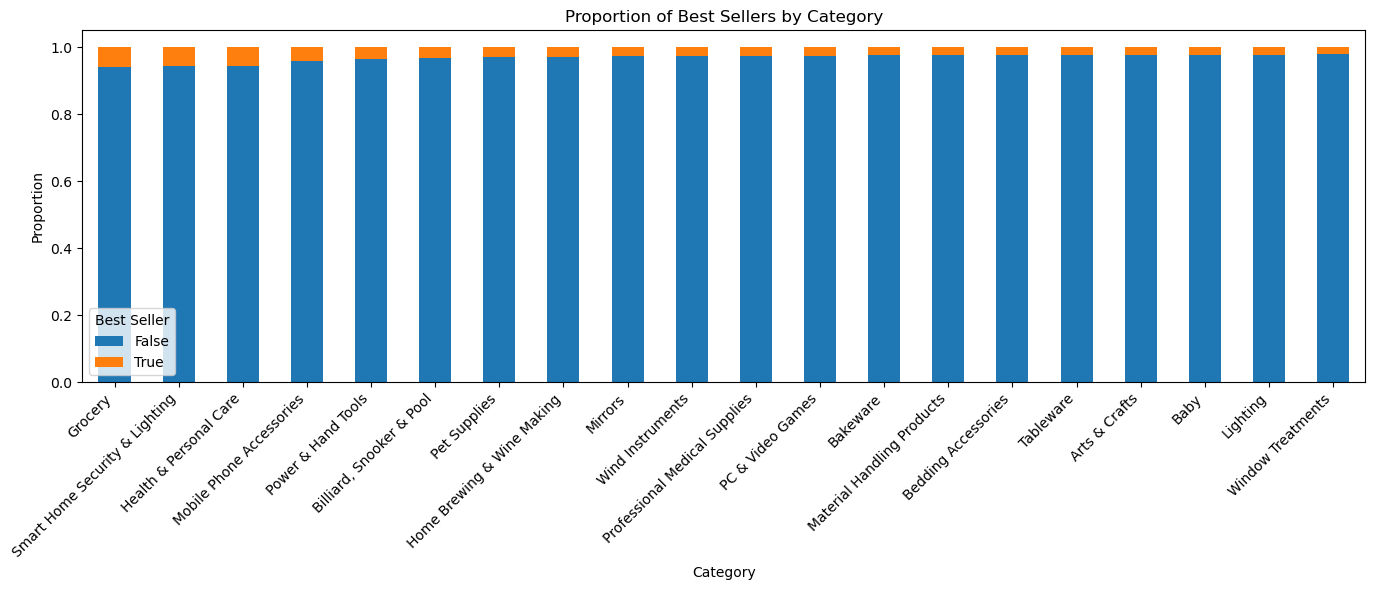

In [10]:
# Stacked Bar Chart
# Top 20 categories with highest bestseller proportion
top20_prop = bestseller_rate.sort_values(True, ascending=False).head(20)

top20_prop.plot(
    kind="bar",
    stacked=True,
    figsize=(14,6)
)

plt.title("Proportion of Best Sellers by Category")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Best Seller")
plt.tight_layout()
plt.show()

In [11]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers

In [12]:
price_outliers = tukeys_test_outliers(df["price"])

price_outliers

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64

In [13]:
price_outliers = tukeys_test_outliers(df["price"])

df_clean = df[~df["price"].isin(price_outliers)]

In [14]:
# Violin Plot - Top 20 categories
top20 = df_clean["category"].value_counts().head(20).index

subset = df_clean[df_clean["category"].isin(top20)]

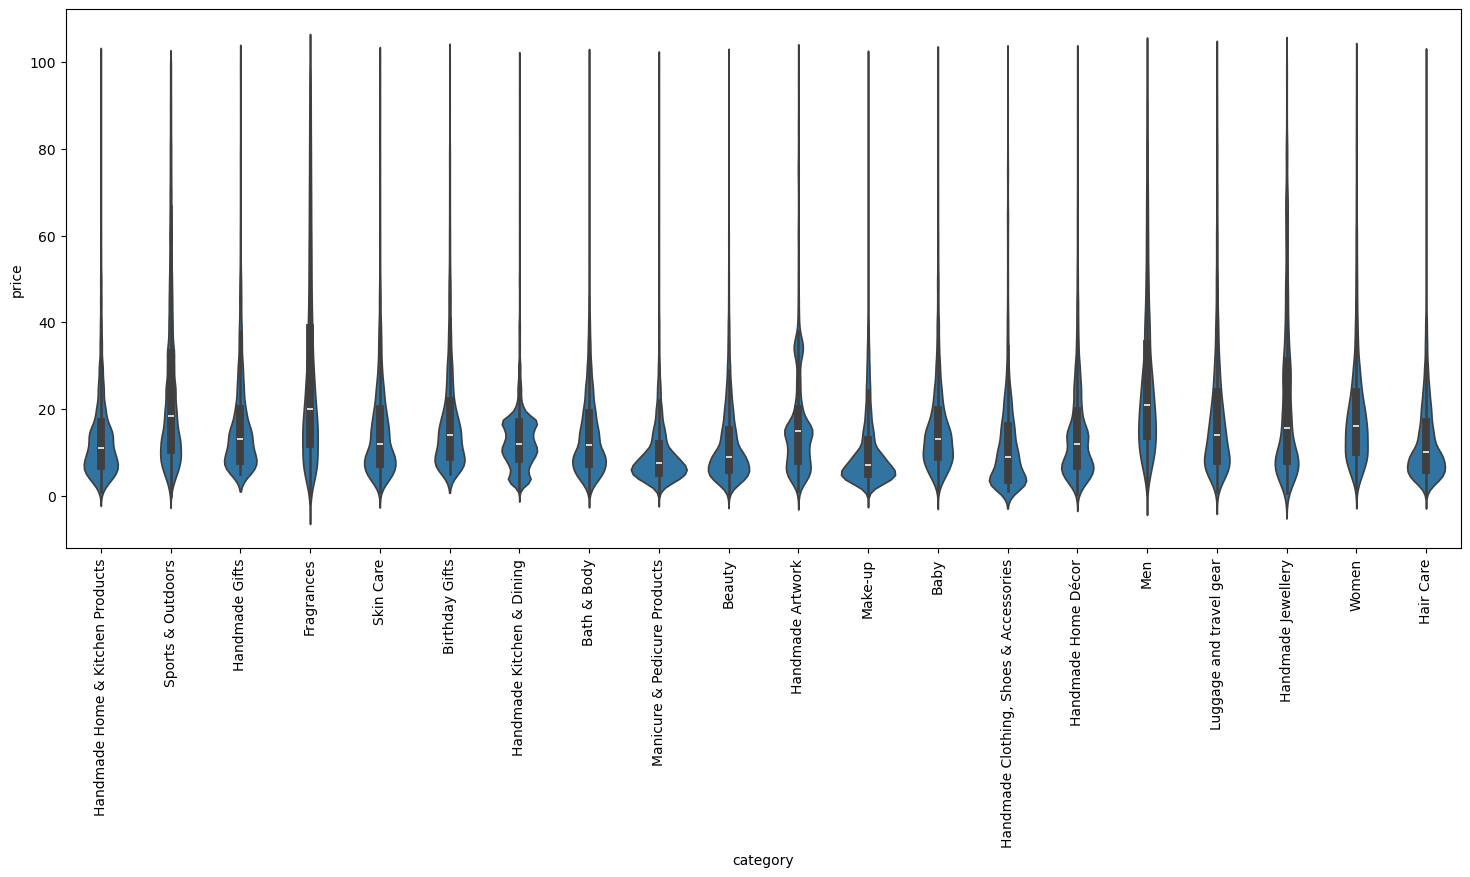

In [15]:
plt.figure(figsize=(18,7))

sns.violinplot(
    data=subset,
    x="category",
    y="price"
)

plt.xticks(rotation=90)

plt.show()

In [16]:
# Highest median price
median_price = (
    df_clean
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price.head()

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

The category with the highest median price is Desktop PCs, with a median price of 74.00. This indicates that products in this category tend to have a higher typical price compared with other categories.

In [17]:
# Average Price - Top 10 categories
top10 = df_clean["category"].value_counts().head(10).index

avg_price = (
    df_clean[df_clean["category"].isin(top10)]
    .groupby("category")["price"]
    .mean()
    .sort_values()
)

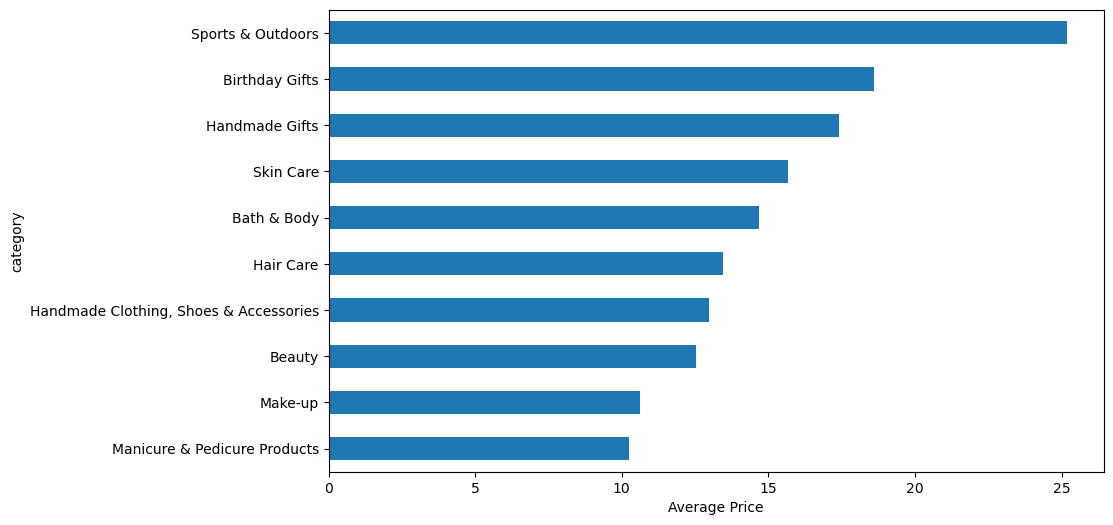

In [18]:
avg_price.plot(
    kind="barh",
    figsize=(10,6)
)

plt.xlabel("Average Price")
plt.show()

In [19]:
# Highest average overall
(
df_clean.groupby("category")["price"]
.mean()
.sort_values(ascending=False)
.head()
)

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

In [20]:
# Ratings Boxplots - Top 10 categories
subset = df_clean[
    df_clean["category"].isin(top10)
]

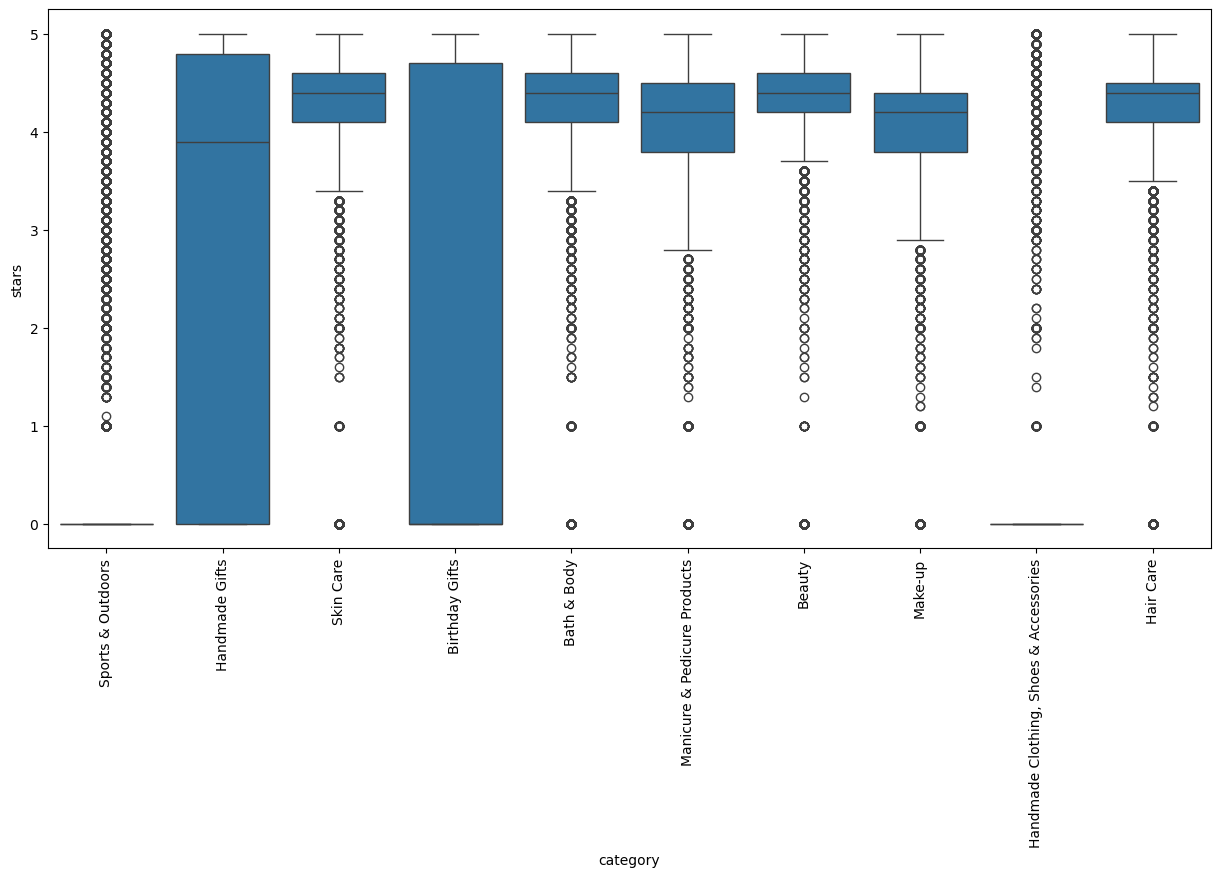

In [21]:
plt.figure(figsize=(15,7))

sns.boxplot(
    data=subset,
    x="category",
    y="stars"
)

plt.xticks(rotation=90)

plt.show()

In [22]:
# Highest median rating
(
df_clean.groupby("category")["stars"]
.median()
.sort_values(ascending=False)
.head()
)

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

In [23]:
# Correlation
r,p = pearsonr(
    df_clean["price"],
    df_clean["stars"]
)

print(r)
print(p)

-0.0776729987818118
0.0


The Pearson correlation test shows a statistically significant relationship between product price and rating (p < 0.05). However, the correlation coefficient (r = -0.078) indicates that the relationship is extremely weak. Therefore, price has little practical influence on product ratings.

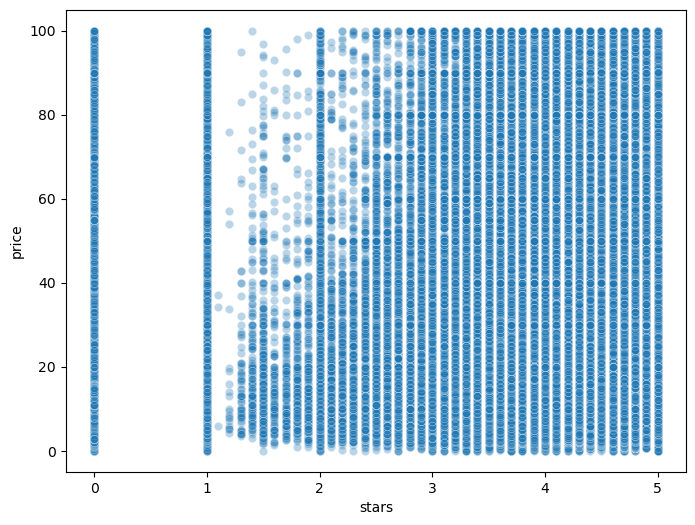

In [24]:
# Scatter Plot
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_clean,
    x="stars",
    y="price",
    alpha=0.3
)

plt.show()

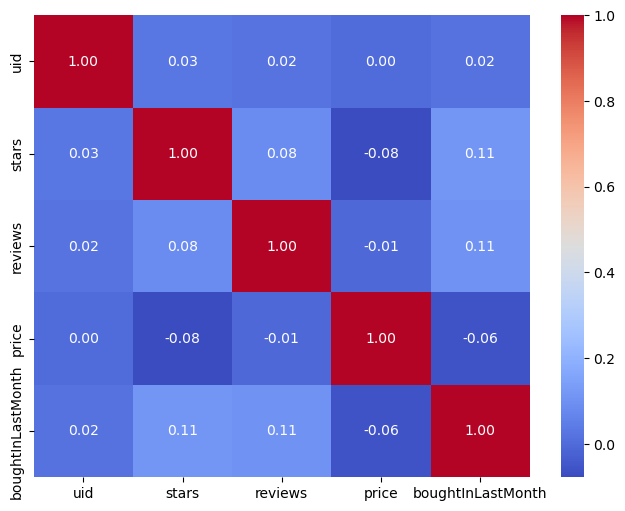

In [25]:
# Correlation Heatmap
numeric = df_clean.select_dtypes(include=np.number)

plt.figure(figsize=(8,6))

sns.heatmap(
    numeric.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

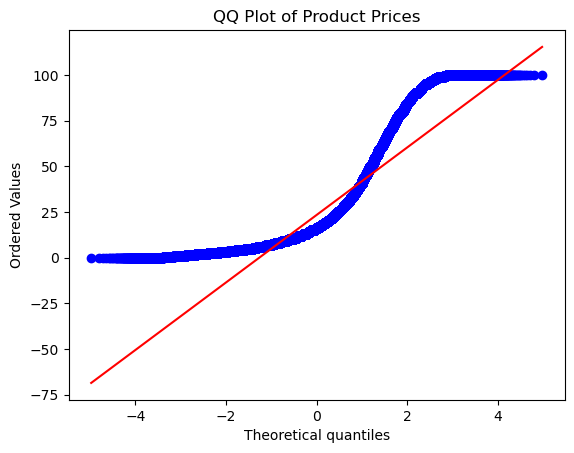

In [26]:
# QQ Plot
stats.probplot(df_clean["price"], dist="norm", plot=plt)

plt.title("QQ Plot of Product Prices")

plt.show()

## Bonus

In [27]:
# Violin Plot - Top 20 categories with the outliers
top20_ot = df["category"].value_counts().head(20).index

subset2 = df[df["category"].isin(top20_ot)]

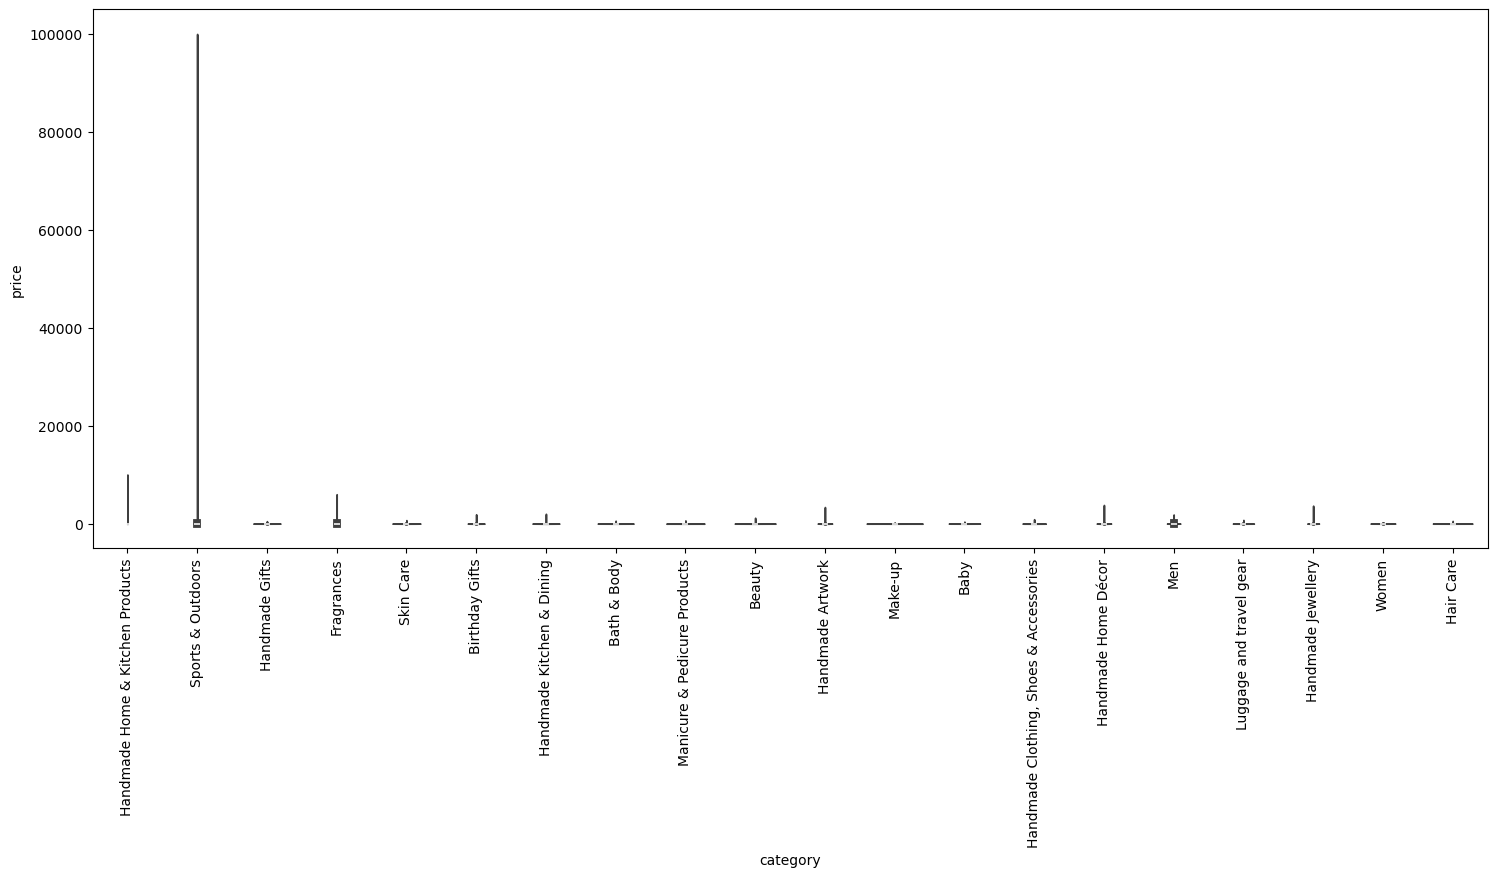

In [28]:
plt.figure(figsize=(18,7))

sns.violinplot(
    data=subset2,
    x="category",
    y="price"
)

plt.xticks(rotation=90)

plt.show()

In [29]:
# Highest median price with the outliers
median_price2 = (
    df
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price2.head()

category
Laptops                      1042.725
Desktop PCs                   810.400
Snowboards                    366.725
Home Audio Record Players     326.080
3D Printers                   319.000
Name: price, dtype: float64

In [30]:
# Average Price - Top 10 categories with the outliers
top10_ot = df["category"].value_counts().head(10).index

avg_price2 = (
    df[df["category"].isin(top10_ot)]
    .groupby("category")["price"]
    .mean()
    .sort_values()
)

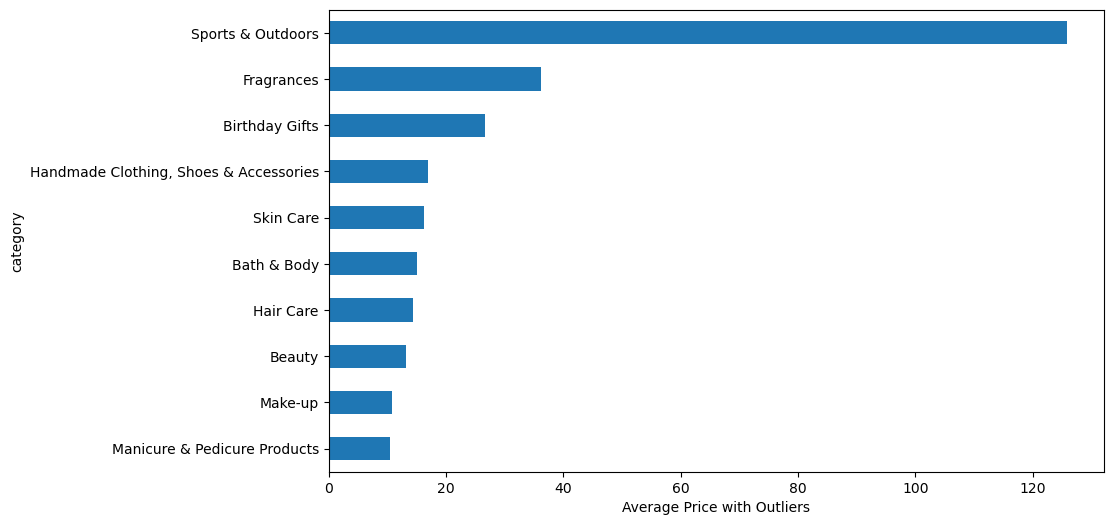

In [31]:
avg_price2.plot(
    kind="barh",
    figsize=(10,6)
)

plt.xlabel("Average Price with Outliers")
plt.show()

In [32]:
# Highest average overall with outliers
(
df.groupby("category")["price"]
.mean()
.sort_values(ascending=False)
.head()
)

category
Laptops                  1087.987827
3D Printers              1018.036129
Desktop PCs               926.816064
Home Office Furniture     622.135898
Test & Measurement        559.382973
Name: price, dtype: float64

In [33]:
# Ratings Boxplots - Top 10 categories with outliers
subset3 = df[
    df["category"].isin(top10_ot)
]

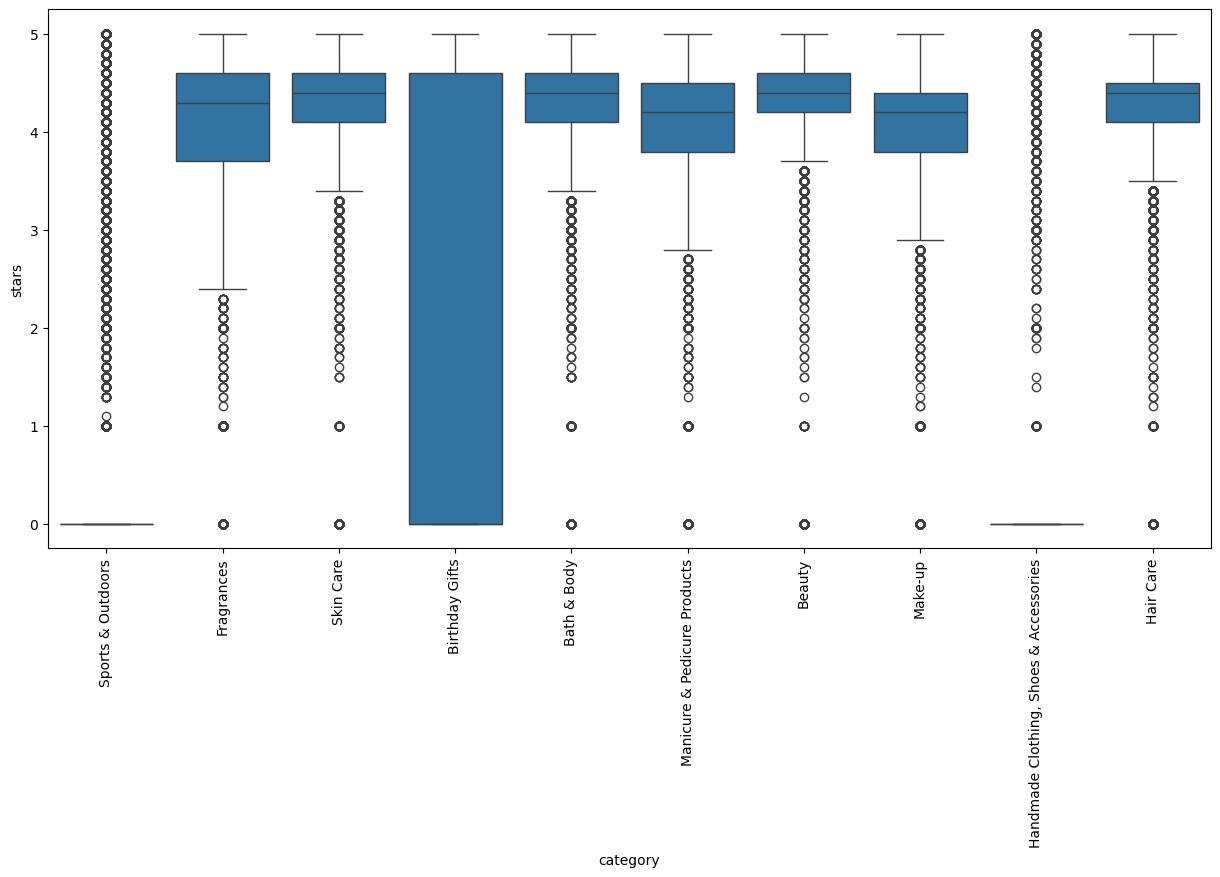

In [34]:
plt.figure(figsize=(15,7))

sns.boxplot(
    data=subset3,
    x="category",
    y="stars"
)

plt.xticks(rotation=90)

plt.show()

In [35]:
# Highest median rating with outliers
(
df.groupby("category")["stars"]
.median()
.sort_values(ascending=False)
.head()
)

category
Computer Memory                 4.7
CPUs                            4.6
Building & Construction Toys    4.6
Laptop Accessories              4.6
Hobbies                         4.6
Name: stars, dtype: float64

In [37]:
# Correlation with outliers
r,p = pearsonr(
    df["price"],
    df["stars"]
)

print(r)
print(p)

-0.12490673262148638
0.0


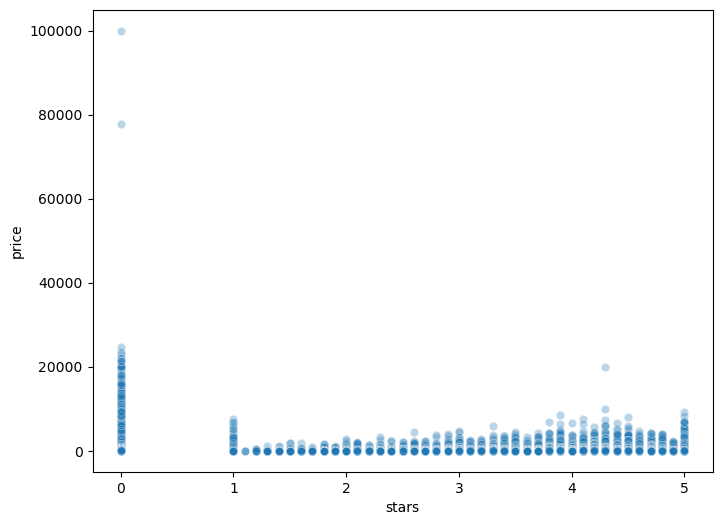

In [38]:
# Scatter Plot with outliers
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="stars",
    y="price",
    alpha=0.3
)

plt.show()

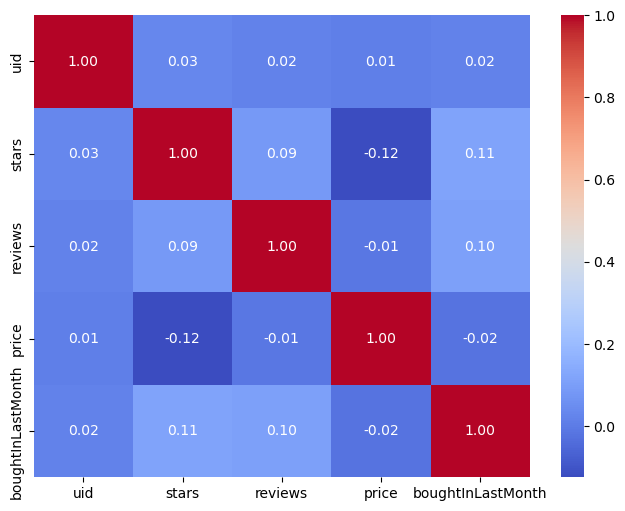

In [39]:
# Correlation Heatmap with outliers
numeric1 = df.select_dtypes(include=np.number)

plt.figure(figsize=(8,6))

sns.heatmap(
    numeric1.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

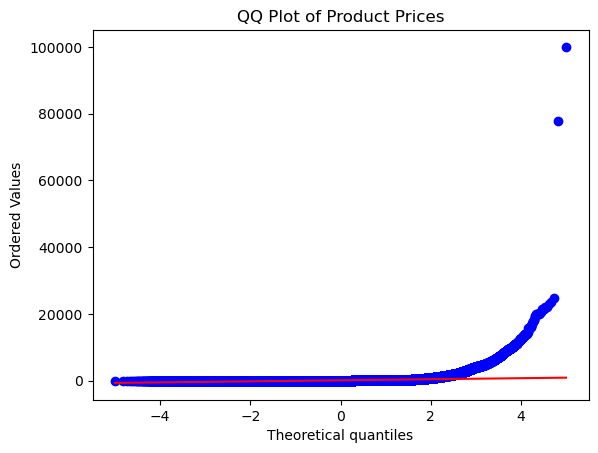

In [40]:
# QQ Plot with outliers
stats.probplot(df["price"], dist="norm", plot=plt)

plt.title("QQ Plot of Product Prices")

plt.show()

Removing outliers mainly improves the analysis of product prices by reducing the influence of extremely expensive products on average values and visualizations. Median prices and customer ratings remain largely unchanged because they are robust to outliers. The relationship between price and customer ratings remains weak regardless of whether outliers are included, indicating that product price alone is not a reliable predictor of customer satisfaction.